---
title: "Redesigning Morocco's unemployment map for every reader"
author:
  - name: "Souheil Mouhajir"
    affiliation: "Elliott School of International Affairs, The George Washington University"
date: "2026-11-12"
date-modified: "2026-11-12"
abstract: |
  The week 8 choropleth of Morocco's 2024 census unemployment used the red, green and gold of the Moroccan flag. Under simulated deuteranopia, the two end classes of that palette, which mean opposite things (10.6 percent and 31.5 percent unemployment), sit only 9 units apart in CAM02-UCS colour space. This notebook tests six palettes under three simulated colour vision deficiencies and in grayscale, replaces the flag colours with the ColorBrewer purple to orange diverging scheme, adds hatching and value labels so that colour is never the only cue, and verifies the result with the Machado et al. (2009) simulator and WCAG 2.1 contrast ratios.
keywords: [colour accessibility, colour vision deficiency, choropleth, ColorBrewer, colorcet, CAM02-UCS, WCAG, Morocco, RGPH 2024]
language:
  title-block-published: "Published"
  title-block-modified: "Created"
format:
  html:
    theme: litera
    title-block-banner: images/banner.svg
    title-block-banner-color: white
    linkcolor: darkgreen
    smooth-scroll: true
    embed-resources: true
    toc: true
    toc-depth: 2
    toc-title: "Contents"
    code-fold: true
    code-summary: "Show code"
    fig-cap-location: bottom
execute:
  warning: false
  message: false
jupyter: python3
---

## The visualization being redesigned

The week 8 assignment mapped the census unemployment rate of Morocco's 12 regions from the **2024 General Census of Population and Housing (RGPH 2024)** of the **Haut-Commissariat au Plan (HCP)**. The national rate was 21.3 percent; the regional rates run from 10.6 percent in Dakhla-Oued Ed-Dahab to 31.5 percent in Guelmim-Oued Noun (HCP, 2024). The map sorted regions into five classes centred on the national rate and coloured them with the red, green and gold of the Moroccan flag: two greens below the national rate, gold just under it and two reds above it.

That palette has a known flaw. Red and green are the two hues that the most common colour vision deficiencies confuse, and **Birch (2012)** puts red-green deficiency at about 8 percent of men and 0.4 percent of women of European ancestry, and between 4 and 6.5 percent of Chinese and Japanese men. On a map whose whole message is "green is below the national rate, red is above it", a reader with deuteranopia loses the message. This notebook measures that loss, picks a replacement palette by testing six candidates, and checks the redesign with a colour vision simulator and a contrast calculation.

## Setup

The data pipeline is the one from week 8: boundaries from the **geoBoundaries API** (Runfola et al., 2020), cached in `data/`, joined on ISO codes to the HCP census table. Colour vision deficiency is simulated with **colorspacious**, which implements the model of **Machado, Oliveira and Fernandes (2009)**. Colour differences are measured in **CAM02-UCS** (Luo, Cui and Li, 2006), a colour space built so that equal distances look roughly equally different to a viewer with normal vision.

In [1]:
#| label: setup
#| code-fold: false
import os
import json
import itertools
import urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import mapclassify
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib_scalebar.scalebar import ScaleBar
import colorcet
import colorspacious
from colorspacious import cspace_convert, deltaE
NATIONAL_RATE = 21.3
BREAKS = [10.6, 15, 20, 21.3, 25, 31.5]
EQUAL_AREA = "ESRI:102022"

In [2]:
#| label: load-data
os.makedirs("data", exist_ok=True)
boundary_path = "data/mar_adm1.geojson"
api_url = "https://www.geoboundaries.org/api/current/gbOpen/MAR/ADM1/"
if not os.path.exists(boundary_path):
    try:
        with urllib.request.urlopen(api_url, timeout=30) as response:
            record = json.load(response)
        urllib.request.urlretrieve(record["simplifiedGeometryGeoJSON"], boundary_path)
    except Exception as error:
        print("API not reachable, using the GitHub release instead:", error)
        github_url = "https://media.githubusercontent.com/media/wmgeolab/geoBoundaries/main/releaseData/gbOpen/MAR/ADM1/geoBoundaries-MAR-ADM1_simplified.geojson"
        urllib.request.urlretrieve(github_url, boundary_path)
regions = gpd.read_file(boundary_path)
regions = regions[["shapeISO", "geometry"]].rename(columns={"shapeISO": "iso_code"})
census = pd.read_csv("data/regions_rgph2024.csv")
capitals = pd.read_csv("data/regional_capitals.csv")
gdf = regions.merge(census, on="iso_code", how="left", validate="one_to_one")
assert gdf["unemployment_rate_2024"].notna().all()
gdf_eq = gdf.to_crs(EQUAL_AREA)
points = gpd.GeoDataFrame(capitals, geometry=gpd.points_from_xy(capitals["lon"], capitals["lat"]), crs="EPSG:4326")
points_eq = points.to_crs(EQUAL_AREA)
gdf_eq["class_id"] = mapclassify.UserDefined(gdf_eq["unemployment_rate_2024"], bins=BREAKS[1:]).yb
print("Regions joined:", len(gdf_eq))
print("Regions per class:", [int(n) for n in np.bincount(gdf_eq["class_id"], minlength=5)])

Regions joined: 12
Regions per class: [1, 4, 1, 2, 4]


## Before: the week 8 map

The cell below redraws the week 8 static map with its original code and colours.

In [3]:
#| label: draw-functions
week8_colors = ["darkgreen", "yellowgreen", "gold", "indianred", "firebrick"]
week8_labels = ["10.6 to 15.0 (well below)", "15.0 to 20.0 (below)", "20.0 to 21.3 (just below)", "21.3 to 25.0 (above)", "25.0 to 31.5 (well above)"]
def draw_before(ax):
    gdf_eq.plot(column="unemployment_rate_2024", cmap=ListedColormap(week8_colors), scheme="UserDefined", classification_kwds={"bins": BREAKS[1:]}, edgecolor="white", linewidth=0.8, legend=True, legend_kwds={"title": "Unemployment rate (%)", "loc": "lower right", "labels": week8_labels, "frameon": False}, ax=ax)
    gdf_eq.dissolve().boundary.plot(ax=ax, color="black", linewidth=0.8)
    points_eq.plot(ax=ax, color="gold", edgecolor="black", markersize=30, zorder=3)
    label_offsets = {"Casablanca": (-50, -6)}
    for index, row in points_eq.iterrows():
        offset = label_offsets.get(row["city"], (5, 4))
        ax.annotate(row["city"], xy=(row.geometry.x, row.geometry.y), xytext=offset, textcoords="offset points", fontsize=8, bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.8})
    ax.set_title("Before: week 8 palette", fontsize=13, fontweight="bold", loc="left")
    ax.set_axis_off()

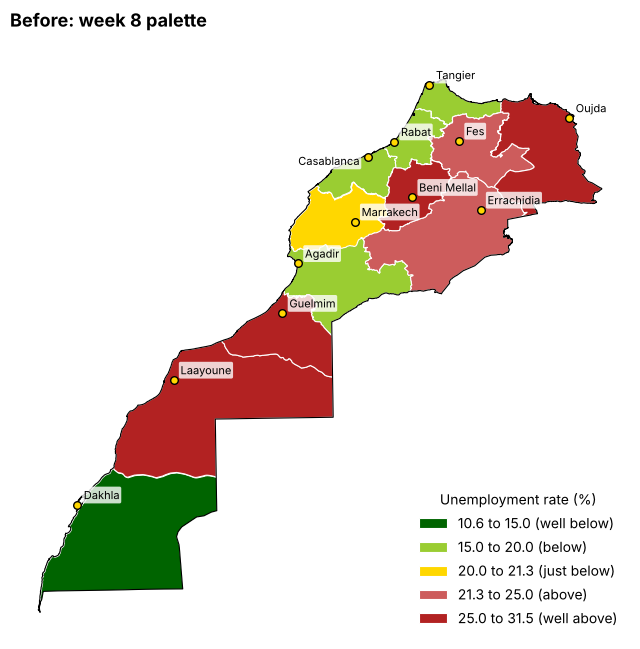

In [4]:
#| label: fig-before
#| fig-cap: "The week 8 map. Census unemployment rate by region, RGPH 2024, in five fixed classes centred on the national rate of 21.3 percent. Source: HCP (2024); geoBoundaries (Runfola et al., 2020)."
fig, ax = plt.subplots(figsize=(8, 9))
draw_before(ax)
plt.show()

## Testing six palettes

Six candidate palettes go through the same test. Each is cut into five colours: three below the national rate and two above it. Every colour is then passed through the Machado simulator for deuteranopia, protanopia and tritanopia at full severity, and through a perceptual grayscale that keeps only CAM02-UCS lightness. Within each condition the test measures the CAM02-UCS distance between every pair of classes and keeps two numbers: the smallest distance between any two classes, and the distance between the two end classes, which carry opposite meanings.

The candidates are the week 8 flag colours; matplotlib's red, yellow and green scheme (`RdYlGn`), which is the traffic light default many maps use; three ColorBrewer diverging schemes from **Harrower and Brewer (2003)** (`RdBu`, `BrBG` and `PuOr`); and `CET_CBD1`, a diverging map from the **colorcet** collection that **Kovesi (2015)** designed to be perceptually uniform and safe for red-green deficiency.

In [5]:
#| label: palette-test
positions = [0.0, 0.22, 0.40, 0.68, 1.0]
def sample(cmap):
    return [mcolors.to_rgb(cmap(p)) for p in positions]
palettes = {}
palettes["Week 8 flag colours"] = [mcolors.to_rgb(c) for c in week8_colors]
palettes["RdYlGn (traffic light)"] = sample(plt.get_cmap("RdYlGn_r"))
palettes["RdBu (ColorBrewer)"] = sample(plt.get_cmap("RdBu_r"))
palettes["BrBG (ColorBrewer)"] = sample(plt.get_cmap("BrBG_r"))
palettes["PuOr (ColorBrewer)"] = sample(plt.get_cmap("PuOr_r"))
palettes["CET_CBD1 (colorcet)"] = sample(colorcet.cm["CET_CBD1"])
conditions = {"Normal vision": None, "Deuteranopia": "deuteranomaly", "Protanopia": "protanomaly", "Tritanopia": "tritanomaly", "Grayscale": "grayscale"}
def simulate(rgb, condition):
    rgb = np.clip(np.asarray(rgb, dtype=float), 0, 1)
    if condition is None:
        return rgb
    if condition == "grayscale":
        ucs = cspace_convert(rgb, "sRGB1", "CAM02-UCS")
        ucs[..., 1] = 0
        ucs[..., 2] = 0
        return np.clip(cspace_convert(ucs, "CAM02-UCS", "sRGB1"), 0, 1)
    space = {"name": "sRGB1+CVD", "cvd_type": condition, "severity": 100}
    return np.clip(cspace_convert(rgb, space, "sRGB1"), 0, 1)
rows = []
for name, colors in palettes.items():
    for condition, code in conditions.items():
        seen = simulate(colors, code)
        pairs = [deltaE(seen[i], seen[j], input_space="sRGB1") for i, j in itertools.combinations(range(5), 2)]
        ends = deltaE(seen[0], seen[4], input_space="sRGB1")
        rows.append({"Palette": name, "Condition": condition, "Smallest gap": min(pairs), "Gap between end classes": ends})
results = pd.DataFrame(rows)
smallest = results.pivot(index="Palette", columns="Condition", values="Smallest gap")[list(conditions)]
smallest["Worst colour condition"] = smallest[["Normal vision", "Deuteranopia", "Protanopia", "Tritanopia"]].min(axis=1)
smallest.sort_values("Worst colour condition", ascending=False).round(1)

Condition,Normal vision,Deuteranopia,Protanopia,Tritanopia,Grayscale,Worst colour condition
Palette,,,,,,
PuOr (ColorBrewer),30.9,30.6,30.9,24.2,4.2,24.2
RdBu (ColorBrewer),30.2,24.6,24.1,30.5,2.8,24.1
CET_CBD1 (colorcet),16.8,17.5,15.6,14.4,2.0,14.4
BrBG (ColorBrewer),23.9,17.7,14.2,26.6,3.5,14.2
Week 8 flag colours,16.5,9.0,7.0,14.4,7.4,7.0
RdYlGn (traffic light),21.4,8.4,2.4,24.5,0.4,2.4


The table gives, for each palette and condition, the smallest CAM02-UCS distance between any two of the five classes; larger is better. The last column keeps the worst of the four colour conditions. The week 8 colours fall from 16.5 with normal vision to 9.0 under deuteranopia and 7.0 under protanopia, and the traffic light scheme falls to 2.4 under protanopia, which makes two of its classes practically the same colour. Only two palettes keep a smallest gap above 24 under all three simulated deficiencies: `PuOr` (24.2 at worst) and `RdBu` (24.1 at worst). The tie is broken by the next test.

In [6]:
#| label: ends-test
ends = results.pivot(index="Palette", columns="Condition", values="Gap between end classes")[list(conditions)]
ends.loc[["Week 8 flag colours", "RdYlGn (traffic light)", "RdBu (ColorBrewer)", "PuOr (ColorBrewer)", "CET_CBD1 (colorcet)"]].round(1)

Condition,Normal vision,Deuteranopia,Protanopia,Tritanopia,Grayscale
Palette,,,,,
Week 8 flag colours,53.7,9.0,11.4,58.2,7.4
RdYlGn (traffic light),54.3,8.4,15.9,57.3,0.4
RdBu (ColorBrewer),44.8,33.2,24.1,46.9,2.8
PuOr (ColorBrewer),45.1,48.0,44.6,32.9,23.2
CET_CBD1 (colorcet),60.1,60.0,58.5,39.3,2.0


The distance between the end classes is the number that matters most for this map, because those two classes mean "far below" and "far above" the national rate. Under deuteranopia the week 8 darkgreen and firebrick sit 9.0 apart, against 53.7 with normal vision, so a reader with deuteranopia sees the best and worst regions as near twins. `PuOr` keeps them 48.0 apart under deuteranopia and 44.6 under protanopia, where `RdBu` drops to 33.2 and 24.1. In grayscale the `PuOr` ends stay 23.2 apart, against about 3 for `RdBu`, whose dark blue and dark red become almost the same grey. That decides the choice of `PuOr`.

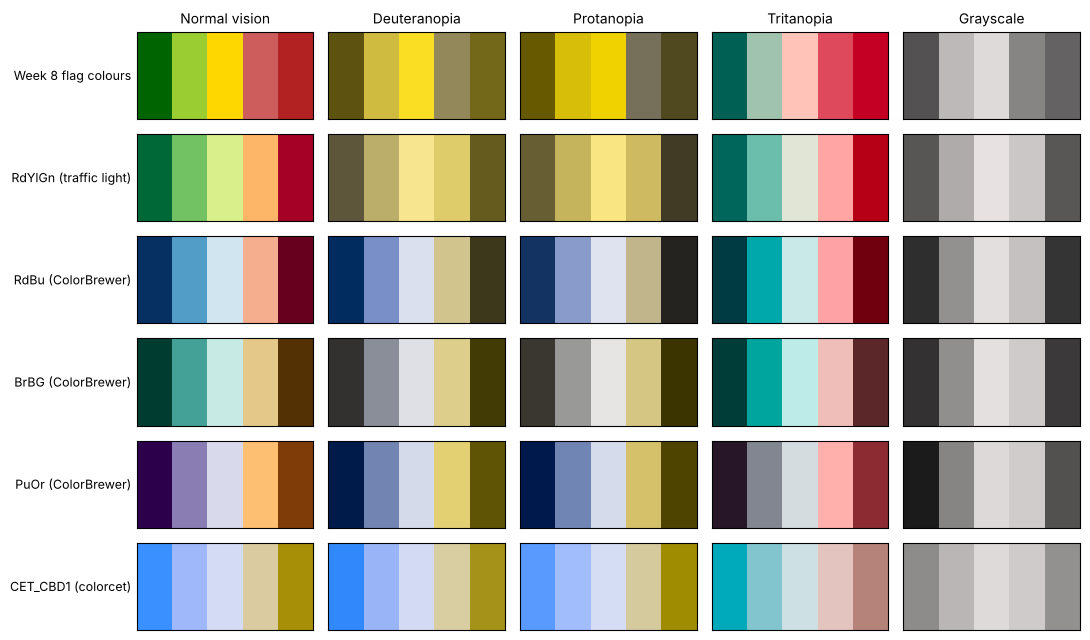

In [7]:
#| label: fig-strips
#| fig-cap: "The six candidate palettes as seen with normal vision, under three simulated colour vision deficiencies (Machado et al., 2009, full severity) and in perceptual grayscale. Each strip shows the five map classes, from well below to well above the national rate."
fig, axes = plt.subplots(len(palettes), len(conditions), figsize=(11, 6.5))
for r, (name, colors) in enumerate(palettes.items()):
    for c, (condition, code) in enumerate(conditions.items()):
        ax = axes[r, c]
        ax.imshow([simulate(colors, code)], aspect="auto")
        ax.set_xticks([])
        ax.set_yticks([])
        if r == 0:
            ax.set_title(condition, fontsize=10)
        if c == 0:
            ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.show()

The strips show the failure directly. In the deuteranopia and protanopia columns the first and last swatches of the week 8 and traffic light palettes turn the same olive brown. `PuOr` keeps its two ends apart in every column: navy against olive under deuteranopia and protanopia, dark purple against dark red under tritanopia. The grayscale column shows the weakness that every palette here shares: the two ends come out as dark or middle greys, close in tone even for `PuOr`, so grayscale alone cannot say which side of the national rate a region is on. The redesign therefore adds a second cue that survives without colour.

## After: the redesigned map

The redesign makes four changes.

- Colour comes from `PuOr`: purple for regions below the national rate, orange for regions above it, with the lightest tints next to 21.3 percent. Orange is a common warning colour and stays distinct from purple under all three simulated deficiencies.
- The two classes above the national rate carry diagonal hatching, so the above or below reading survives in grayscale and in print, and for readers who cannot separate the hues.
- Region boundaries and hatching are drawn in white on dark fills and in black on light fills. The code picks the colour for each class by computing which of the two has the higher contrast against that fill.
- Each region shows its own rate in a white label, so no reader has to decode a colour to get the number. This follows WCAG 2.1 success criterion 1.4.1, which says colour should not be the only means of conveying information (W3C, 2018).
- City names are gone and the capitals are small black dots. Names were the main source of clutter in the week 8 map, and the value labels now carry the information that matters.

In [8]:
#| label: draw-after
after_colors = palettes["PuOr (ColorBrewer)"]
after_hatches = ["", "", "", "///", "///"]
after_labels = ["10.6 to 15.0, well below", "15.0 to 20.0, below", "20.0 to 21.3, just below", "21.3 to 25.0, above (hatched)", "25.0 to 31.5, well above (hatched)"]
plt.rcParams["hatch.linewidth"] = 0.8
def luminance(rgb):
    channels = []
    for value in rgb:
        if value <= 0.04045:
            channels.append(value / 12.92)
        else:
            channels.append(((value + 0.055) / 1.055) ** 2.4)
    return 0.2126 * channels[0] + 0.7152 * channels[1] + 0.0722 * channels[2]
def contrast(first, second):
    a = luminance(mcolors.to_rgb(first))
    b = luminance(mcolors.to_rgb(second))
    return (max(a, b) + 0.05) / (min(a, b) + 0.05)
after_lines = []
for color in after_colors:
    if contrast("white", color) >= contrast("black", color):
        after_lines.append("white")
    else:
        after_lines.append("black")
print("Boundary and hatch colour per class:", after_lines)
value_offsets = {"Casablanca-Settat": (-120000, -20000), "Rabat-Sale-Kenitra": (-60000, 30000)}
def draw_after(ax):
    for k in range(5):
        subset = gdf_eq[gdf_eq["class_id"] == k]
        if len(subset) > 0:
            subset.plot(ax=ax, color=after_colors[k], hatch=after_hatches[k], edgecolor=after_lines[k], hatchcolor=after_lines[k], linewidth=1)
    gdf_eq.dissolve().boundary.plot(ax=ax, color="black", linewidth=0.8)
    points_eq.plot(ax=ax, color="black", markersize=8, zorder=3)
    for index, row in gdf_eq.iterrows():
        spot = row.geometry.representative_point()
        dx, dy = value_offsets.get(row["region"], (0, 0))
        ax.text(spot.x + dx, spot.y + dy, f"{row['unemployment_rate_2024']:.1f}", ha="center", va="center", fontsize=9, fontweight="bold", color="black", bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "dimgrey", "linewidth": 0.5}, zorder=4)
    handles = [Patch(facecolor=after_colors[k], hatch=after_hatches[k], edgecolor=after_lines[k], hatchcolor=after_lines[k], label=after_labels[k]) for k in range(5)]
    ax.legend(handles=handles, title="Unemployment rate (%)\nnational rate 21.3", loc="lower right", frameon=False, fontsize=9, title_fontsize=9)
    ax.add_artist(ScaleBar(1, units="m", location="lower left", box_alpha=0))
    ax.set_title("After: PuOr palette with hatching and labels", fontsize=13, fontweight="bold", loc="left")
    ax.set_axis_off()

Boundary and hatch colour per class: ['white', 'black', 'black', 'black', 'white']


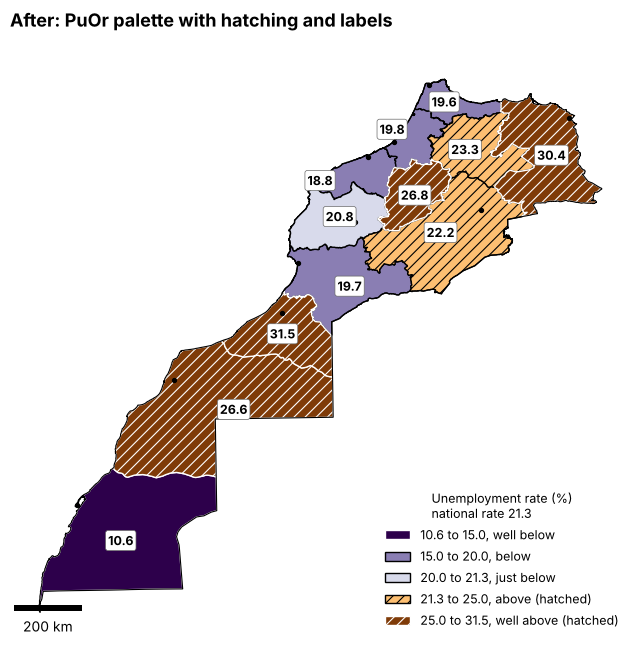

In [9]:
#| label: fig-after
#| fig-cap: "The redesigned map. Census unemployment rate by region, RGPH 2024. Purple regions are below the national rate of 21.3 percent and orange, hatched regions are above it; each label gives the regional rate in percent. Black dots are regional capitals. Projection: Africa Albers Equal Area. Source: HCP (2024); geoBoundaries (Runfola et al., 2020)."
fig, ax = plt.subplots(figsize=(8, 9))
draw_after(ax)
plt.show()

## Before and after

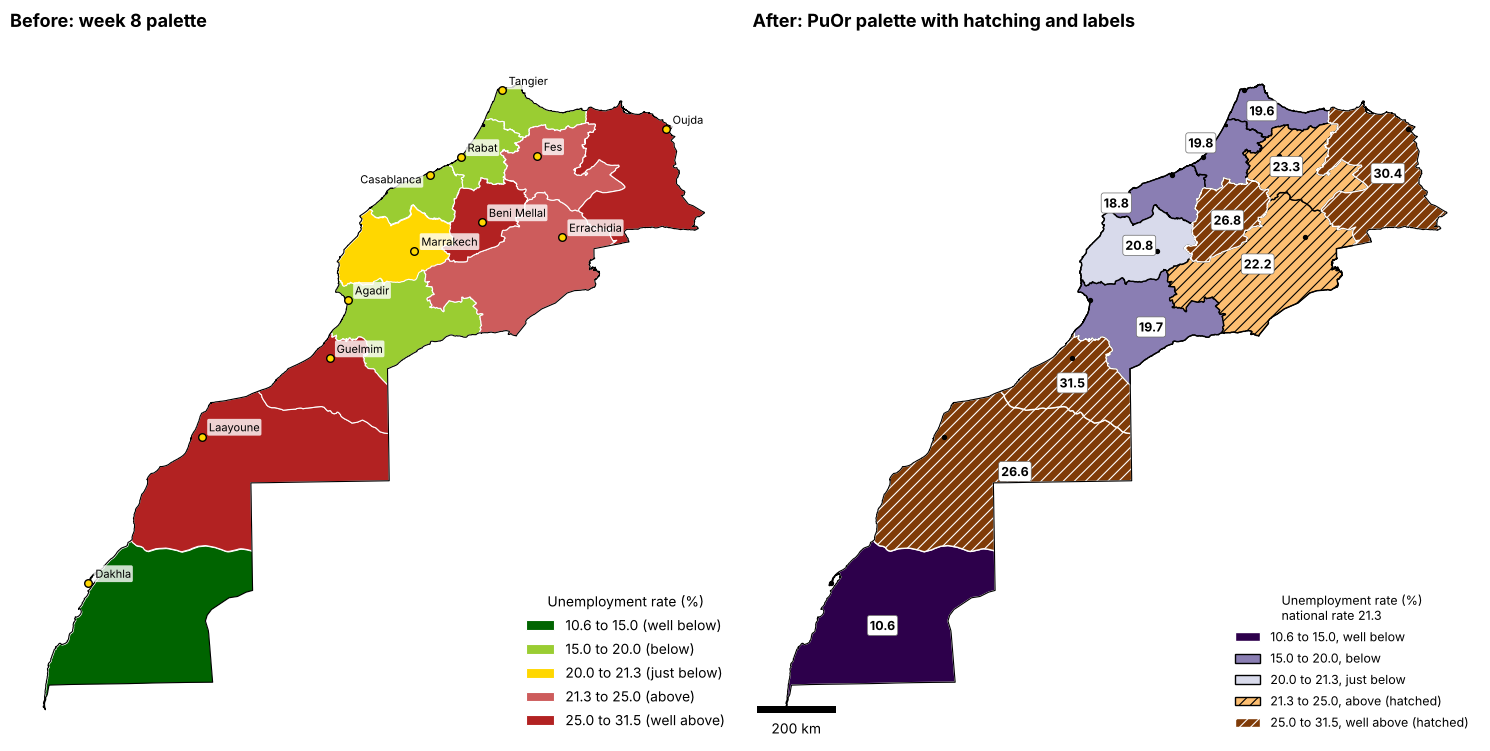

In [10]:
#| label: fig-compare
#| fig-cap: "Before and after with normal vision. Left: the week 8 flag colours. Right: the redesign with the ColorBrewer PuOr palette, hatching above the national rate and value labels."
fig, axes = plt.subplots(1, 2, figsize=(15, 8.5))
draw_before(axes[0])
draw_after(axes[1])
plt.tight_layout()
plt.show()

## Accessibility verification

### Simulated colour vision

Both maps are rendered to images and every pixel goes through the same simulator used for the palette test. This checks the whole map: fills, boundaries, labels and legend together.

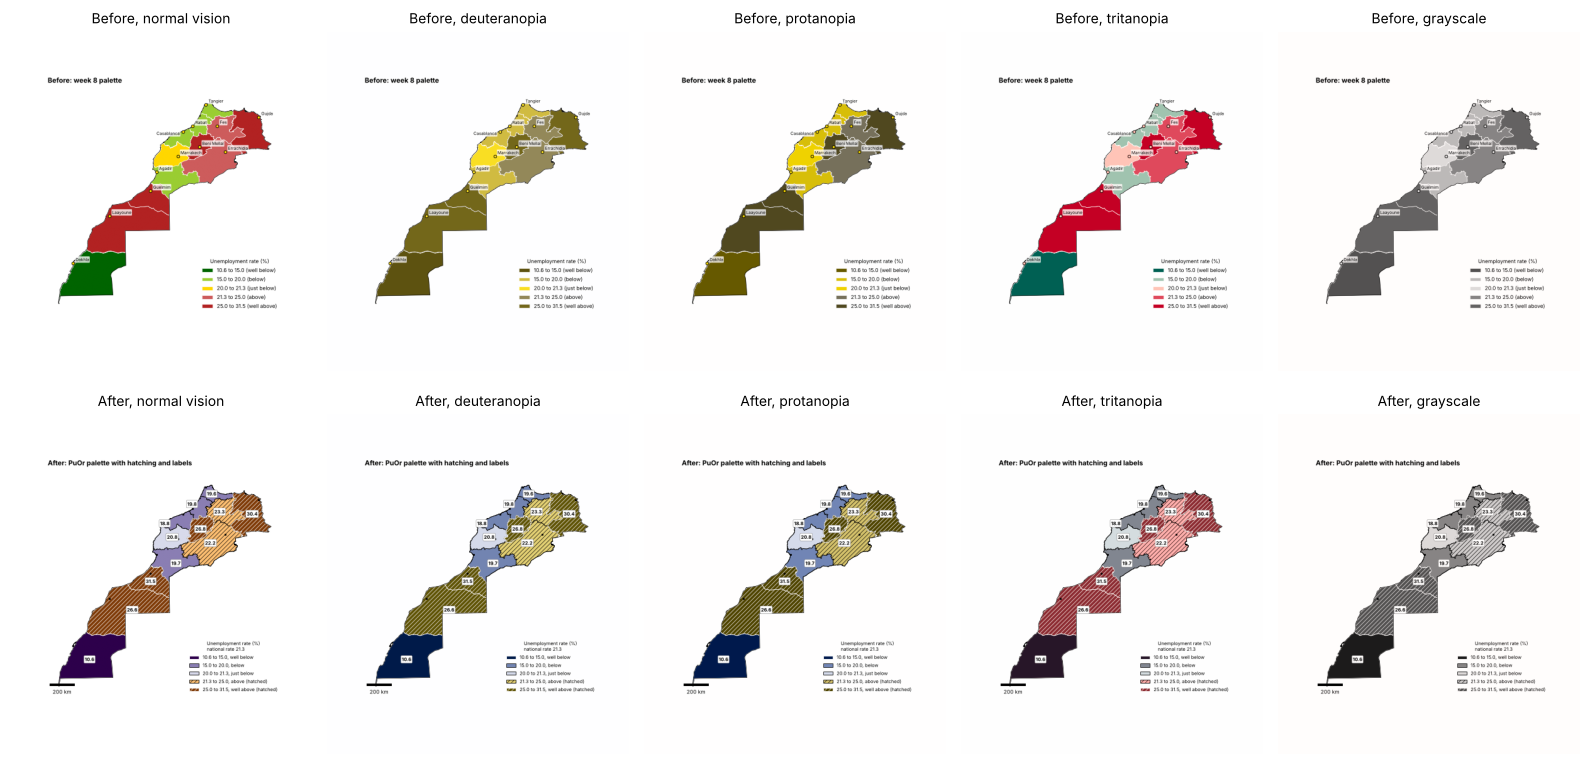

In [11]:
#| label: fig-simulated
#| fig-cap: "Both maps under simulated colour vision deficiency (Machado et al., 2009, full severity) and in perceptual grayscale. Top row: the week 8 map. Bottom row: the redesign."
def render(draw):
    fig, ax = plt.subplots(figsize=(8, 9), dpi=60)
    draw(ax)
    fig.canvas.draw()
    image = np.asarray(fig.canvas.buffer_rgba())[:, :, :3] / 255
    plt.close(fig)
    return image
images = {"Before": render(draw_before), "After": render(draw_after)}
fig, axes = plt.subplots(2, len(conditions), figsize=(16, 8))
for r, (version, image) in enumerate(images.items()):
    for c, (condition, code) in enumerate(conditions.items()):
        ax = axes[r, c]
        ax.imshow(simulate(image, code))
        ax.set_axis_off()
        ax.set_title(f"{version}, {condition.lower()}", fontsize=10)
plt.tight_layout()
plt.show()

In the deuteranopia and protanopia panels of the week 8 map, Guelmim-Oued Noun and the Oriental (above 30 percent) take the same muddy tone as Dakhla-Oued Ed-Dahab (10.6 percent). In the redesign those regions stay clearly apart from Dakhla-Oued Ed-Dahab in every column, and in grayscale the hatching marks them as above the national rate.

### Contrast ratios

The second check uses the **WCAG 2.1** contrast ratio, computed from the relative luminance of two colours. WCAG asks for at least 4.5 to 1 between text and its background and at least 3 to 1 for graphical objects that a reader needs to tell apart (W3C, 2018). The first table checks the label text against its white box and the boundary and hatch colour of each class against that class's fill.

In [12]:
#| label: contrast
checks = []
checks.append({"Element": "Value label text on its white box", "Line colour": "black", "Ratio": contrast("black", "white"), "WCAG minimum": 4.5})
for k in range(5):
    checks.append({"Element": f"Boundary and hatching, class {k + 1}", "Line colour": after_lines[k], "Ratio": contrast(after_lines[k], after_colors[k]), "WCAG minimum": 3.0})
contrast_table = pd.DataFrame(checks)
contrast_table["Passes"] = contrast_table["Ratio"] >= contrast_table["WCAG minimum"]
contrast_table.round(2)

,Element,Line colour,Ratio,WCAG minimum,Passes
0,Value label text on its white box,black,21.00,4.5,True
1,"Boundary and hatching, class 1",white,17.31,3.0,True
2,"Boundary and hatching, class 2",black,5.72,3.0,True
3,"Boundary and hatching, class 3",black,15.15,3.0,True
4,"Boundary and hatching, class 4",black,12.88,3.0,True
5,"Boundary and hatching, class 5",white,8.30,3.0,True


Boundaries matter most where two neighbouring regions fall in the same class, because there the fills are identical and the line is the only thing separating them. The second check finds every such pair from the geometry and tests the line drawn between them. For comparison it also gives the ratio that a plain white boundary, the week 8 choice, would have reached.

In [13]:
#| label: neighbours
pairs = []
for i, j in itertools.combinations(gdf_eq.index, 2):
    touching = gdf_eq.geometry[i].buffer(1000).intersects(gdf_eq.geometry[j])
    same_class = gdf_eq.loc[i, "class_id"] == gdf_eq.loc[j, "class_id"]
    if touching and same_class:
        k = gdf_eq.loc[i, "class_id"]
        pairs.append({"Neighbours in the same class": gdf_eq.loc[i, "region"] + " and " + gdf_eq.loc[j, "region"], "Class": k + 1, "Line colour": after_lines[k], "Ratio": contrast(after_lines[k], after_colors[k]), "Ratio with a white line": contrast("white", after_colors[k])})
neighbour_table = pd.DataFrame(pairs)
neighbour_table.round(2)

,Neighbours in the same class,Class,Line colour,Ratio,Ratio with a white line
0,Laayoune-Sakia El Hamra and Guelmim-Oued Noun,5,white,8.30,8.30
1,Tanger-Tetouan-Al Hoceima and Rabat-Sale-Kenitra,2,black,5.72,3.67
2,Draa-Tafilalet and Fes-Meknes,4,black,12.88,1.63
3,Casablanca-Settat and Rabat-Sale-Kenitra,2,black,5.72,3.67


Every check passes. The value labels reach 21 to 1, the highest ratio possible, because they sit in white boxes with black text whatever the fill below them. The per class choice of line colour matters for one pair: Fes-Meknes and Draa-Tafilalet share the light orange class, and a white line between them would reach only 1.6 to 1, well under the WCAG minimum of 3 to 1. The black line drawn there reaches about 12.9 to 1.

## Discussion

The week 8 map asked readers to sort regions into "below" and "above" the national rate with the one hue contrast that red-green colour vision deficiency removes. The simulation puts a number on the failure: under deuteranopia its end classes sit 9.0 CAM02-UCS units apart, against 53.7 with normal vision, so Dakhla-Oued Ed-Dahab at 10.6 percent and Guelmim-Oued Noun at 31.5 percent look nearly alike. Birch (2012) puts red-green deficiency at about 8 percent of men of European ancestry, so a lecture hall of 100 students would hold several readers who miss the main finding.

The redesign gives the reader three independent cues. `PuOr` was chosen on evidence: only it and `RdBu` kept every pair of classes more than 24 units apart under all three simulated deficiencies, and `PuOr` kept its end classes far further apart (44.6 units under protanopia against 24.1). Hatching marks the classes above the national rate, which keeps the map legible in grayscale and in print. The value labels give each rate in text at a contrast of 21 to 1, so a reader who cannot use colour at all still gets the numbers. Boundary and hatch colours are chosen by contrast for each class, which fixed the one neighbouring pair where a white line failed WCAG.

Colour is now an aid, no longer a requirement. Two weaknesses remain: tritanopia gives `PuOr` its smallest gap (24.2), and in grayscale the distance from the national rate rests on the labels alone.

## Reproducibility

The notebook runs from the files in this folder. The only network call is the geoBoundaries API request, made once when `data/mar_adm1.geojson` is missing. The palette test, both maps, the simulations and the contrast table are all computed when the notebook runs. The cell below prints the package versions used for this render.

In [14]:
#| label: versions
for package in [np, pd, gpd, matplotlib, mapclassify, colorspacious, colorcet]:
    print(package.__name__.ljust(14), package.__version__)

numpy          2.5.3
pandas         3.0.5
geopandas      1.2.0
matplotlib     3.11.2
mapclassify    2.11.0
colorspacious  1.1.2
colorcet       3.2.1


From the folder in PowerShell, the notebook renders to HTML with:

```
pip install -r requirements.txt
quarto render week9_assignment.ipynb --execute
```

## References

Birch, J. (2012) 'Worldwide prevalence of red-green color deficiency', *Journal of the Optical Society of America A*, 29(3), pp. 313-320. doi:10.1364/JOSAA.29.000313.

Haut-Commissariat au Plan (2024) *Recensement General de la Population et de l'Habitat 2024: principaux resultats*. Rabat: HCP, 17 December.

Harrower, M. and Brewer, C.A. (2003) 'ColorBrewer.org: an online tool for selecting colour schemes for maps', *The Cartographic Journal*, 40(1), pp. 27-37.

Kovesi, P. (2015) 'Good colour maps: how to design them', *arXiv*, 1509.03700.

Luo, M.R., Cui, G. and Li, C. (2006) 'Uniform colour spaces based on CIECAM02 colour appearance model', *Color Research and Application*, 31(4), pp. 320-330.

Machado, G.M., Oliveira, M.M. and Fernandes, L.A.F. (2009) 'A physiologically-based model for simulation of color vision deficiency', *IEEE Transactions on Visualization and Computer Graphics*, 15(6), pp. 1291-1298.

Runfola, D. et al. (2020) 'geoBoundaries: a global database of political administrative boundaries', *PLoS ONE*, 15(4), e0231866.

W3C (2018) *Web Content Accessibility Guidelines (WCAG) 2.1*. World Wide Web Consortium Recommendation, 5 June. Available at: https://www.w3.org/TR/WCAG21/.